In [165]:
import sys

import numpy as np 
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

In [166]:
def analyze_stability(delta, gamma):
    J = np.array([[0, 1],
                  [-gamma, -2 * delta]])

    eigenvalues, eigenvectors = np.linalg.eig(J)
    lam1, lam2 = eigenvalues

    if np.isclose(lam1.imag, 0) and np.isclose(lam2.imag, 0):
        lam1, lam2 = lam1.real, lam2.real
        if lam1 < 0 and lam2 < 0:
            stability = "Устойчивый узел"
            color_point = 'blue'
        elif lam1 > 0 and lam2 > 0:
            stability = "Неустойчивый узел"
            color_point = 'red'
        elif lam1 * lam2 < 0:
            stability = "Седло"
            color_point = 'red'
        else:
            stability = "Негрубое равновесие"
            color_point = 'green'
    else:
        real_part = lam1.real
        if np.isclose(real_part, 0):
            stability = "Центр"
            color_point = 'green'
        elif real_part < 0:
            stability = "Устойчивый фокус"
            color_point = 'blue'
        else:
            stability = "Неустойчивый фокус"
            color_point = 'red'

    return {
        "stability": stability,
        "eigenvalues": eigenvalues,
        "eigenvectors": eigenvectors,
        "color_point": color_point
    }

In [ ]:
def plot_separatrices(analysis, length=1.0):
    eigenvalues = np.asarray(analysis["eigenvalues"])
    eigenvectors = np.asarray(analysis["eigenvectors"])

    if analysis["stability"] in ("Устойчивый фокус", "Неустойчивый фокус", "Центр"):
        return

    eigenvalues = eigenvalues.real

    for i, lam in enumerate(eigenvalues):
        vec = eigenvectors[:, i].real
        vec = vec / np.linalg.norm(vec)

        color = 'blue' if lam < 0 else 'red'
        sign = np.sign(lam) if lam != 0 else 1   

        for direction in (+1, -1):
            start = direction * vec * length
            if (analysis["stability"] in ("Неустойчивый узел") or ((lam > 0) and (analysis["stability"] in ("Седло")))):
                start = [0,0]
            flow = sign * direction * vec

            u = flow[0] * length
            v = flow[1] * length

            plt.quiver(start[0], start[1], u, v,
                       color=color, alpha=0.9,
                       angles='xy', scale_units='xy', scale=1,
                       width=0.004, headwidth=4, headlength=7,
                       zorder=5)

In [168]:
def f1(gamma, delta):
    def rhs(t, y):
        x, v = y
        return [v, -gamma * x - 2 * delta * v]
    return rhs

In [169]:
def eq_quiver(rhs, limits, N=16):
    xlims, ylims = limits

    xs = np.linspace(xlims[0], xlims[1], N)
    ys = np.linspace(ylims[0], ylims[1], N)

    U = np.zeros((N, N))
    V = np.zeros((N, N))

    for i, y in enumerate(ys):
        for j, x in enumerate(xs):
            vfield = rhs(0.0, [x, y])
            u, v = vfield
            U[i][j] = u
            V[i][j] = v

    X, Y = np.meshgrid(xs, ys)
    return X, Y, U, V

def plotonplane(rhs, limits):
    xlims, ylims = limits
    plt.xlim(xlims[0], xlims[1])
    plt.ylim(ylims[0], ylims[1])
    X, Y, U, V = eq_quiver(rhs, limits)
    plt.quiver(X, Y, U, V, alpha=0.8)

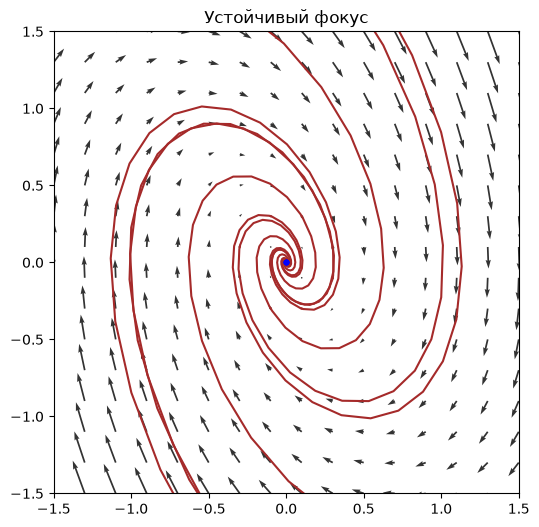

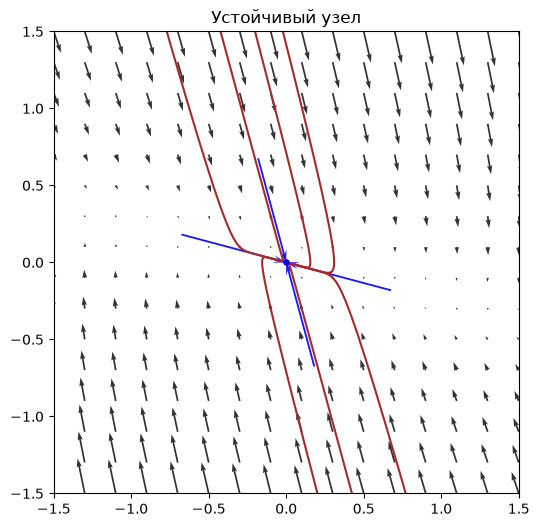

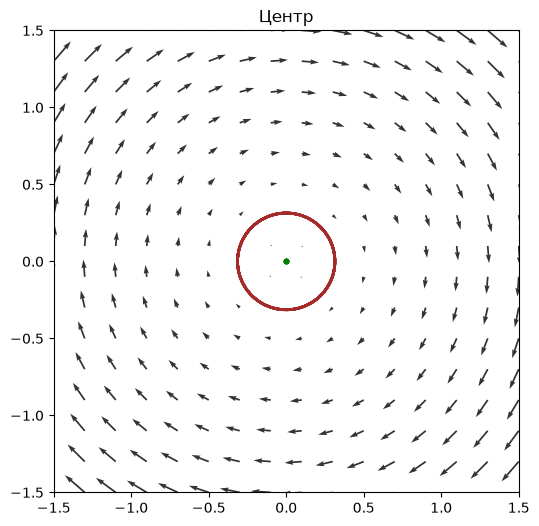

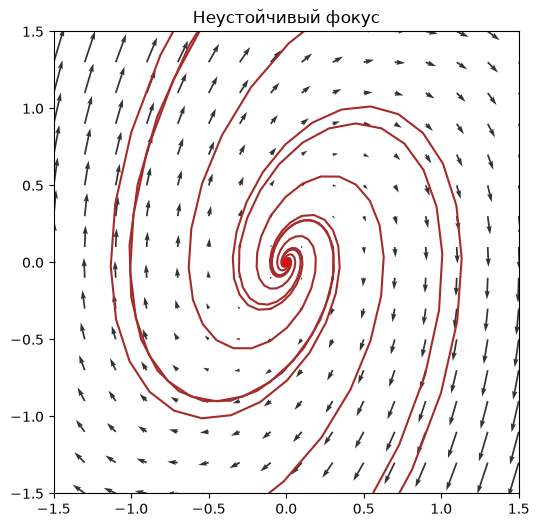

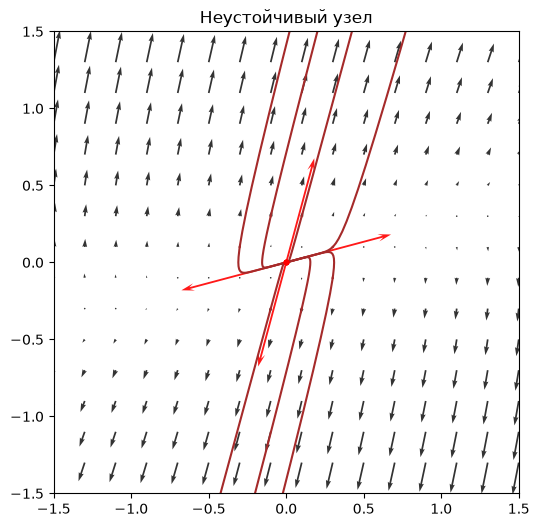

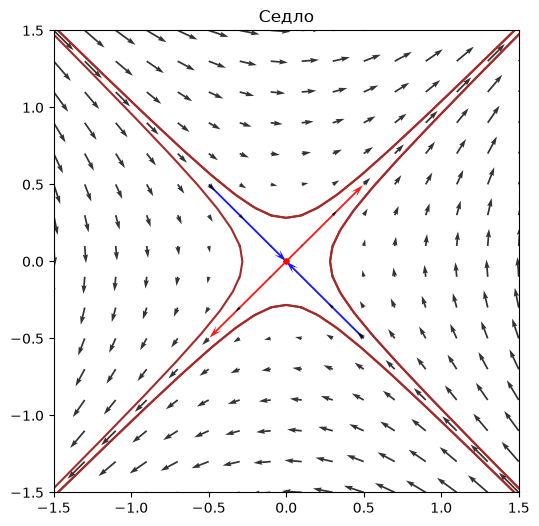

In [ ]:
params = [(0.5, 2.0),(2.0, 1.0),(0.0, 1.0),(-0.5, 2.0),(-2.0, 1.0),(0.0, -1.0)]
starts = [(0.3,  0.1), (0.3, -0.1),(-0.3, 0.1), (0.1,  0.3), (-0.1,  0.3),(0.1, -0.3), (-0.1, -0.3),]
limits = [(-3, 3), (-3, 3)]
for delta, gamma in params:
    plt.figure(figsize=(6, 6)) 
    info = analyze_stability(delta, gamma)
    limits = [(-1.5, 1.5), (-1.5, 1.5)]
    rhs = f1(gamma,delta)
    plotonplane(rhs, limits)
    plot_separatrices(info, length=0.7)
    for x0, y0 in starts:
        sol1 = solve_ivp(rhs, [0.,  25.], (x0, y0), method = 'RK45', rtol=1e-12, color = 'black')
        x1, y1 = sol1.y
        plt.plot(x1, y1, color = 'black')
        sol2 = solve_ivp(rhs, [0., - 25.], (x0, y0), method = 'RK45', rtol=1e-12 , color = 'black')
        x2, y2 = sol2.y
        plt.plot(x2, y2, color = 'black')
        plt.plot(0, 0, 'o', color=info["color_point"], markersize=3, zorder=5)
        plt.title(f'{info["stability"]}')
plt.show()
